  Unnamed: 0   Oil  Density  Crispy  Fracture  Hardness
0       B110  16.5     2955      10        23        97
1       B136  17.7     2660      14         9       139
2       B171  16.2     2870      12        17       143
3       B192  16.7     2920      10        31        95
4       B225  16.3     2975      11        26       143
<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  50 non-null     str    
 1   Oil         50 non-null     float64
 2   Density     50 non-null     int64  
 3   Crispy      50 non-null     int64  
 4   Fracture    50 non-null     int64  
 5   Hardness    50 non-null     int64  
dtypes: float64(1), int64(4), str(1)
memory usage: 2.5 KB
None
Unnamed: 0    0
Oil           0
Density       0
Crispy        0
Fracture      0
Hardness      0
dtype: int64
            Oil     Density     Crispy   Fracture    Hardness
min   13.70

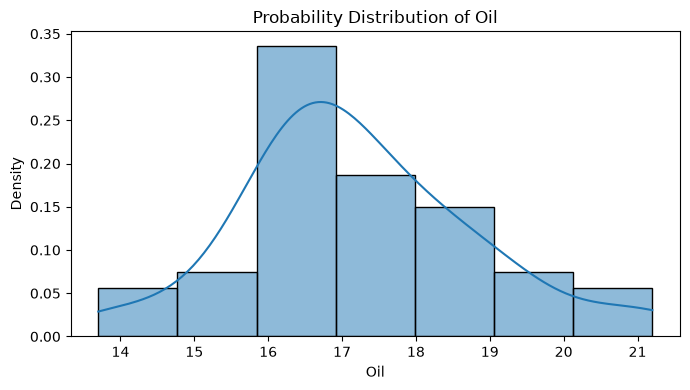

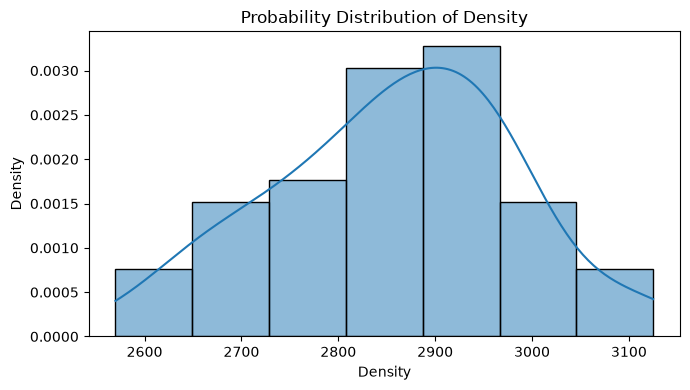

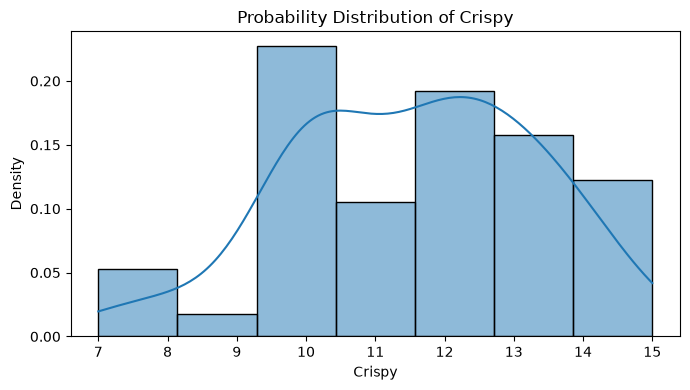

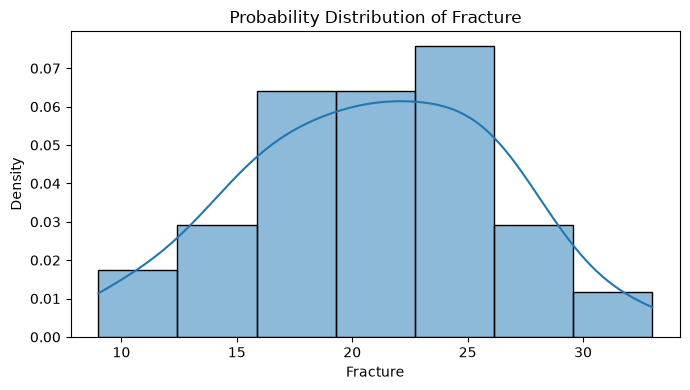

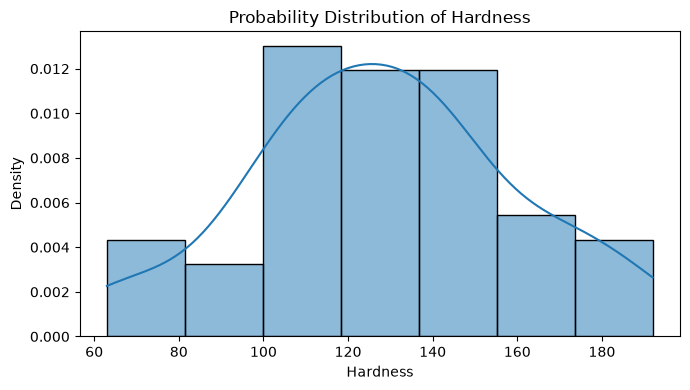

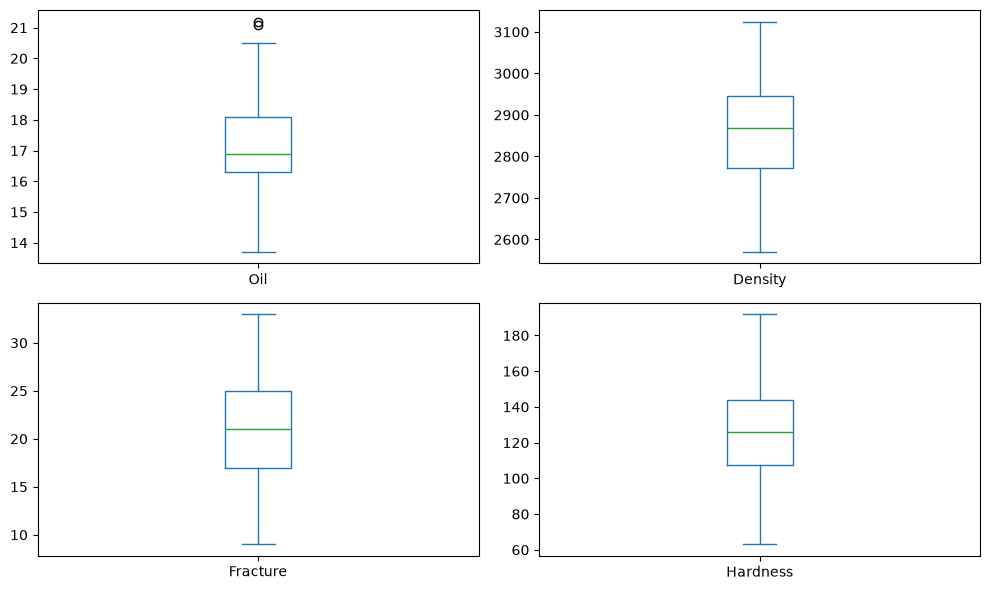

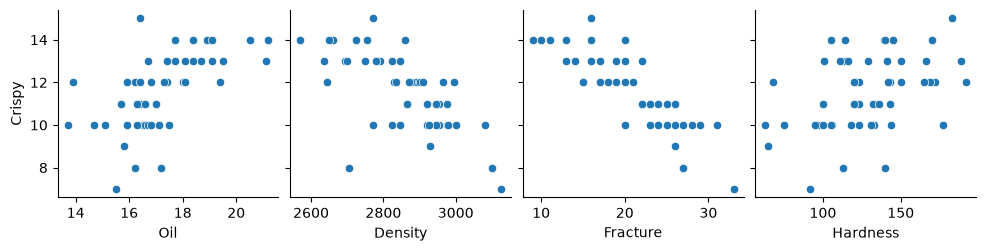

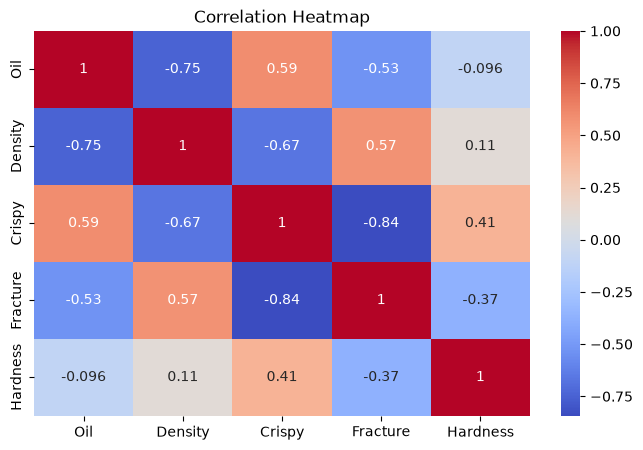

In [15]:


import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv(r"C:\Users\bda\ghanavi\APS-LAB\food_tenture\food-texture.csv")

# Target and features
X = df[['Oil', 'Density', 'Fracture', 'Hardness']]
y = df['Crispy']

# 1. Basic information
print(df.head())
print(df.info())
print(df.isnull().sum())

print(df[['Oil', 'Density', 'Crispy',
          'Fracture', 'Hardness']].agg(
    ['min', 'max', 'std', 'mean']
))



# 3. Probability distribution graphs
features = ['Oil', 'Density', 'Crispy', 'Fracture', 'Hardness']

for col in features:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=col, kde=True, stat='density', bins=7)
    plt.title(f'Probability Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Density')
    plt.tight_layout()
    plt.show()

# 4. Boxplots
X.plot(kind='box', subplots=True, layout=(2, 2),
       figsize=(10, 6))
plt.tight_layout()
plt.show()

# 5. Pairwise scatter plots with Crispy as target
features = ['Oil', 'Density', 'Fracture', 'Hardness', 'Crispy']

sns.pairplot(
    df[features],
    x_vars=['Oil', 'Density', 'Fracture', 'Hardness'],
    y_vars=['Crispy'],
    kind='scatter',
    diag_kind=None
)

plt.show()
# 2. Correlation heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(df.iloc[:, 1:].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()


In [16]:

# 6. Multiple Linear Regression Model

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Select features and target
X = df[['Oil', 'Density', 'Fracture', 'Hardness']]
y = df['Crispy']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict Crispy values
y_pred = model.predict(X_test)

# Display results
print("Intercept:", model.intercept_)
print("Coefficients:")
for feature, coef in zip(X.columns, model.coef_):
    print(feature, ":", coef)

print("Actual Crispy values:", list(y_test))
print("Predicted Crispy values:", y_pred.round(2))

# Evaluate the model
print("Mean Absolute Error (MAE):", mean_absolute_error(y_test, y_pred))
print("Mean Squared Error (MSE):", mean_squared_error(y_test, y_pred))
print("R-squared (R2):", r2_score(y_test, y_pred))


Intercept: 22.131314599809016
Coefficients:
Oil : 0.1832865252187817
Density : -0.004323588958061139
Fracture : -0.1619206521477668
Hardness : 0.01548917015707339
Actual Crispy values: [12, 10, 10, 11, 12, 13, 10, 12, 7, 14]
Predicted Crispy values: [11.4   9.75  9.65 10.6  12.25 13.53  9.94 12.91  7.54 14.27]
Mean Absolute Error (MAE): 0.41778314464263994
Mean Squared Error (MSE): 0.22613103287578143
R-squared (R2): 0.9352060077719824


In [17]:

# 6. Linear Regression using Oil and Hardness

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Select only Oil and Hardness
X = df[['Oil', 'Hardness']]
y = df['Crispy']

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict Crispy
y_pred = model.predict(X_test)

# Display coefficients
print("Intercept:", model.intercept_)
print("Oil coefficient:", model.coef_[0])
print("Hardness coefficient:", model.coef_[1])

# Display actual and predicted values
results = pd.DataFrame({
    'Actual Crispy': y_test,
    'Predicted Crispy': y_pred.round(2)
})
print(results)

# Evaluate the model
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))


Intercept: -4.222688836655287
Oil coefficient: 0.7491843703992576
Hardness coefficient: 0.02273065717740439
    Actual Crispy  Predicted Crispy
13             12             10.03
39             10             10.68
30             10             10.10
45             11             10.94
17             12             11.97
48             13             14.22
26             10             10.49
25             12             12.75
32              7              9.48
19             14             13.27
MAE: 0.8502048434847591
MSE: 1.3319070155516373
R2 Score: 0.6183647519909349


In [ ]:
The multiple linear regression model was trained using Oil and Hardness to predict Crispy. The model achieved a low test R² score, 
indicating that these two features do not adequately explain the variation in Crispy for the test samples. Other features, such as Density and Fracture,
 may provide additional predictive information.
However, because the dataset contains only 21 samples, the result should be interpreted cautiously.